# Homework 5: Decision Trees as Interpretable Models

Name: *Pratham Aggarwal* | Github: *prathamaeron* | USC ID: *1537722913*

## Acute Inflammations Dataset

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

columns = [
    "temperature_c",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "urethral_burning",
    "bladder_inflammation",
    "nephritis",
]
data_path = "../data/diagnosis.data"

data = pd.read_csv(
    data_path,
    sep="\t",
    header=None,
    names=columns,
    encoding="utf-16",
    decimal=",",
)

feature_names = columns[:6]
X = data[feature_names].copy()
for feature in feature_names[1:]:
    X[feature] = X[feature].map({"no": 0, "yes": 1})

y = (
    "Bladder inflammation: "
    + data["bladder_inflammation"]
    + "; nephritis: "
    + data["nephritis"]
)
print(f"Observations: {len(data)} | Predictors: {X.shape[1]}")
print("Joint diagnosis counts:")
display(y.value_counts().rename("count").to_frame())

Observations: 120 | Predictors: 6
Joint diagnosis counts:


,count
Bladder inflammation: yes; nephritis: no,40
Bladder inflammation: no; nephritis: yes,31
Bladder inflammation: no; nephritis: no,30
Bladder inflammation: yes; nephritis: yes,19


### (b) Fit and plot a decision tree on the whole data set

Training accuracy: 1.000
Leaves: 6 | Nodes: 11


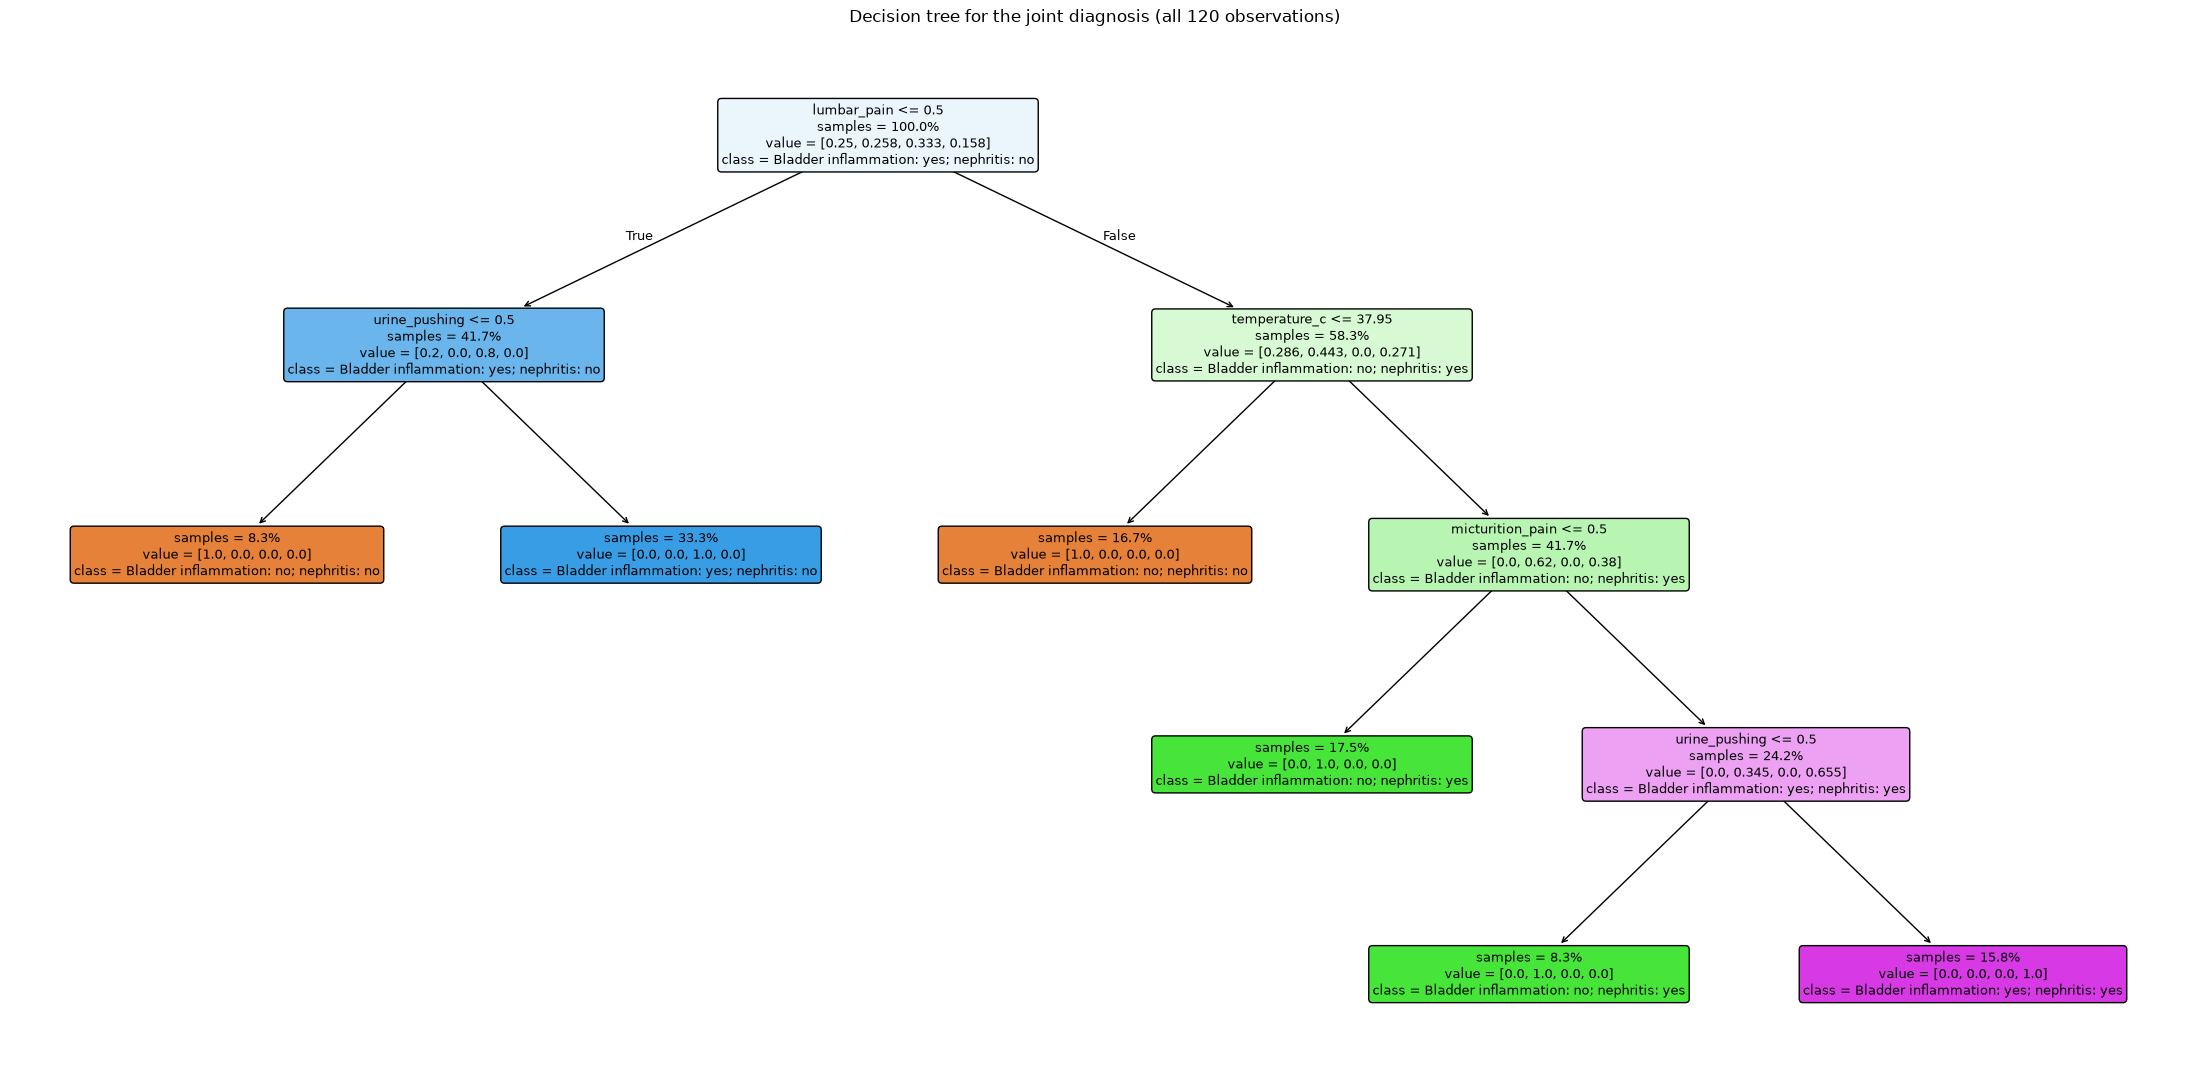

In [2]:
full_tree = DecisionTreeClassifier(random_state=552)
full_tree.fit(X, y)
print(f"Training accuracy: {accuracy_score(y, full_tree.predict(X)):.3f}")
print(f"Leaves: {full_tree.get_n_leaves()} | Nodes: {full_tree.tree_.node_count}")

plt.figure(figsize=(22, 11))
plot_tree(
    full_tree,
    feature_names=feature_names,
    class_names=full_tree.classes_,
    filled=True,
    rounded=True,
    proportion=True,
    impurity=False,
    fontsize=9,
)
plt.title("Decision tree for the joint diagnosis (all 120 observations)")
plt.tight_layout()
plt.show()

### (c) Convert the decision tree into IF-THEN rules

In [3]:
print(export_text(full_tree, feature_names=feature_names, decimals=2))

|--- lumbar_pain <= 0.50
|   |--- urine_pushing <= 0.50
|   |   |--- class: Bladder inflammation: no; nephritis: no
|   |--- urine_pushing >  0.50
|   |   |--- class: Bladder inflammation: yes; nephritis: no
|--- lumbar_pain >  0.50
|   |--- temperature_c <= 37.95
|   |   |--- class: Bladder inflammation: no; nephritis: no
|   |--- temperature_c >  37.95
|   |   |--- micturition_pain <= 0.50
|   |   |   |--- class: Bladder inflammation: no; nephritis: yes
|   |   |--- micturition_pain >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: Bladder inflammation: no; nephritis: yes
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: Bladder inflammation: yes; nephritis: yes



### (d) Cost-complexity pruning and interpretable rules

,ccp_alpha,mean_cv_accuracy,standard_error,leaves,nodes
0,0.0000,0.9917,0.0083,6,11
1,0.0982,0.8583,0.0250,4,7
2,0.1333,0.7667,0.0312,3,5
3,0.1820,0.6750,0.0333,2,3
4,0.2229,0.4833,0.0612,1,1


Selected ccp_alpha=0.000000; one-standard-error threshold=0.983; leaves=6; nodes=11; training accuracy=1.000


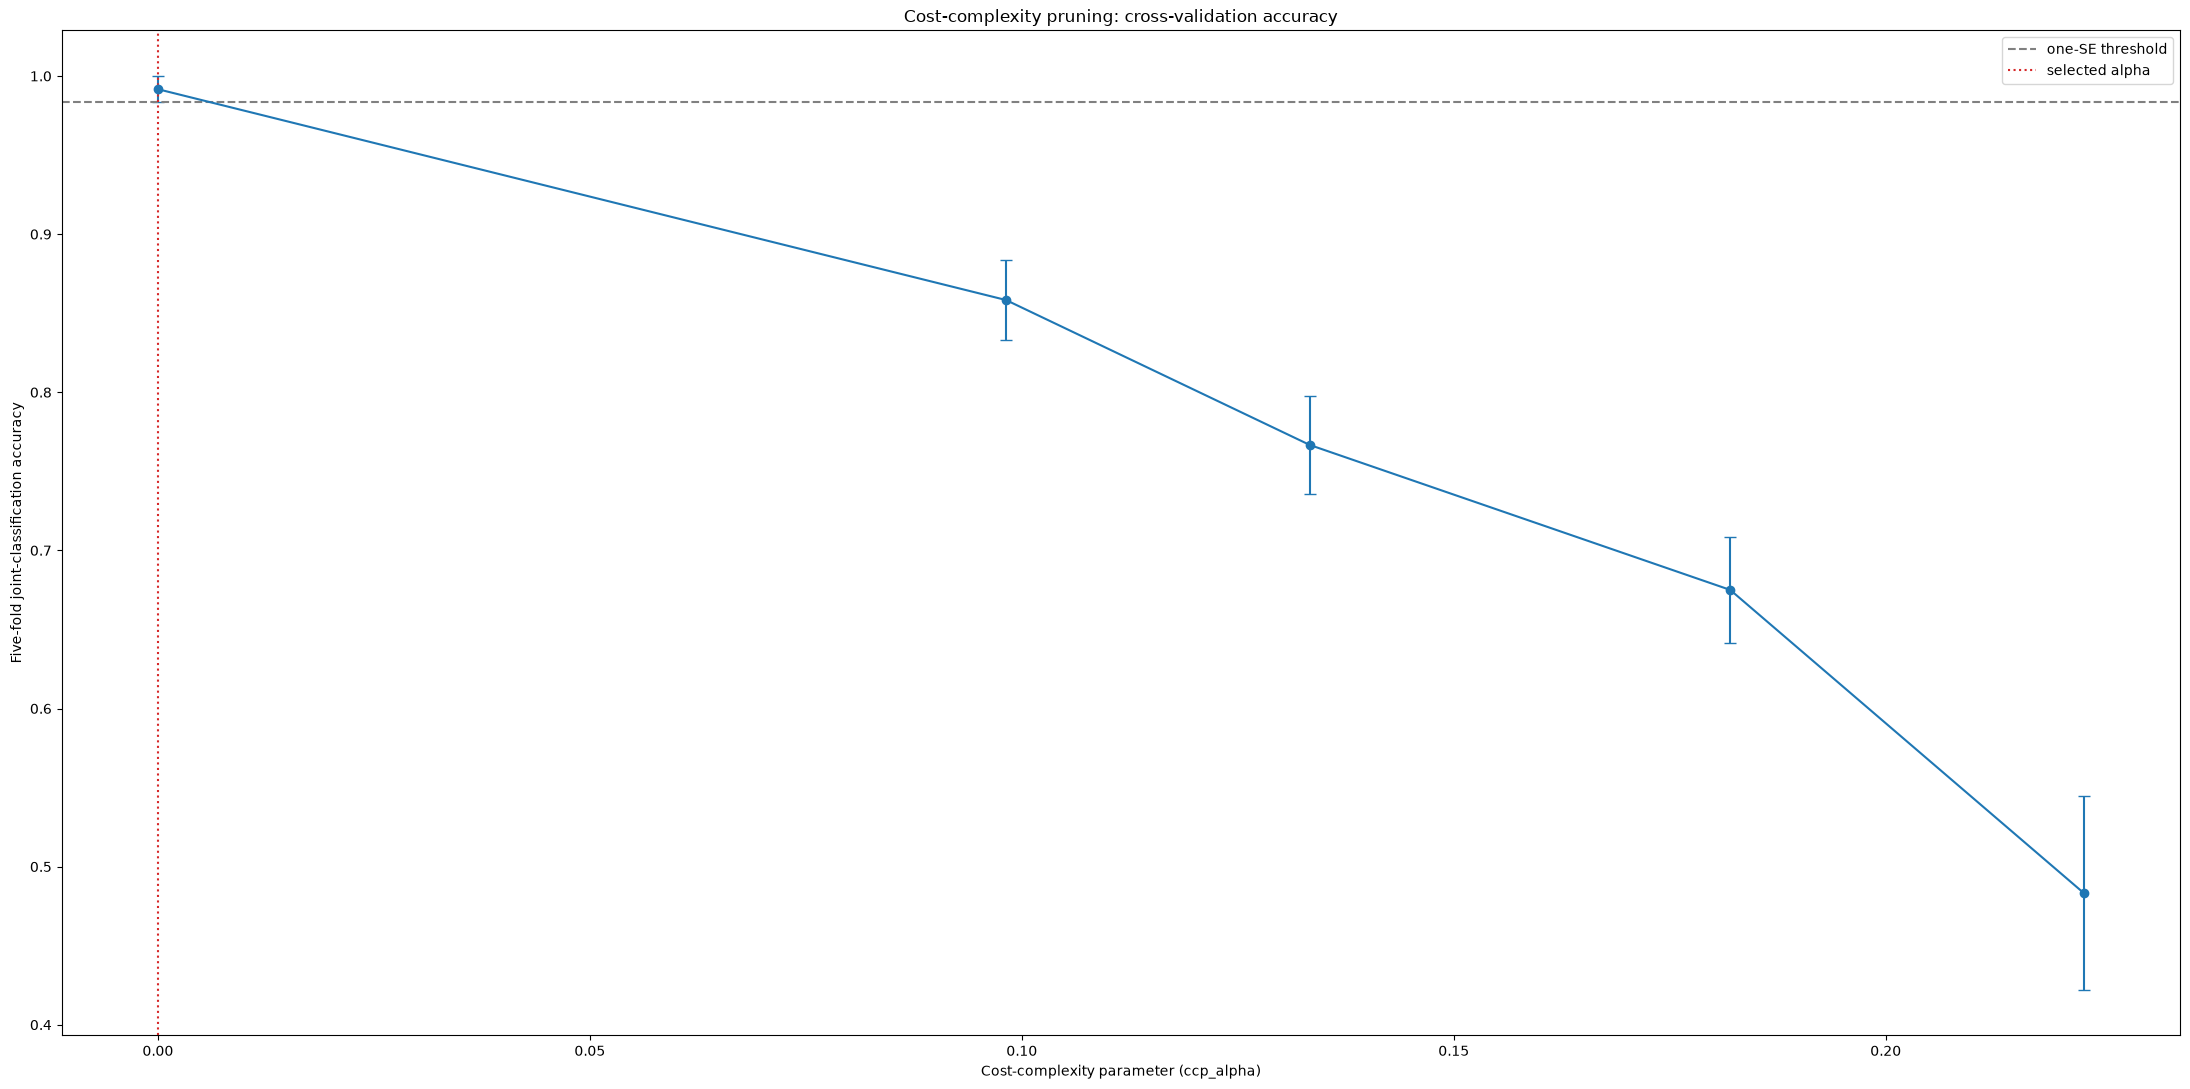

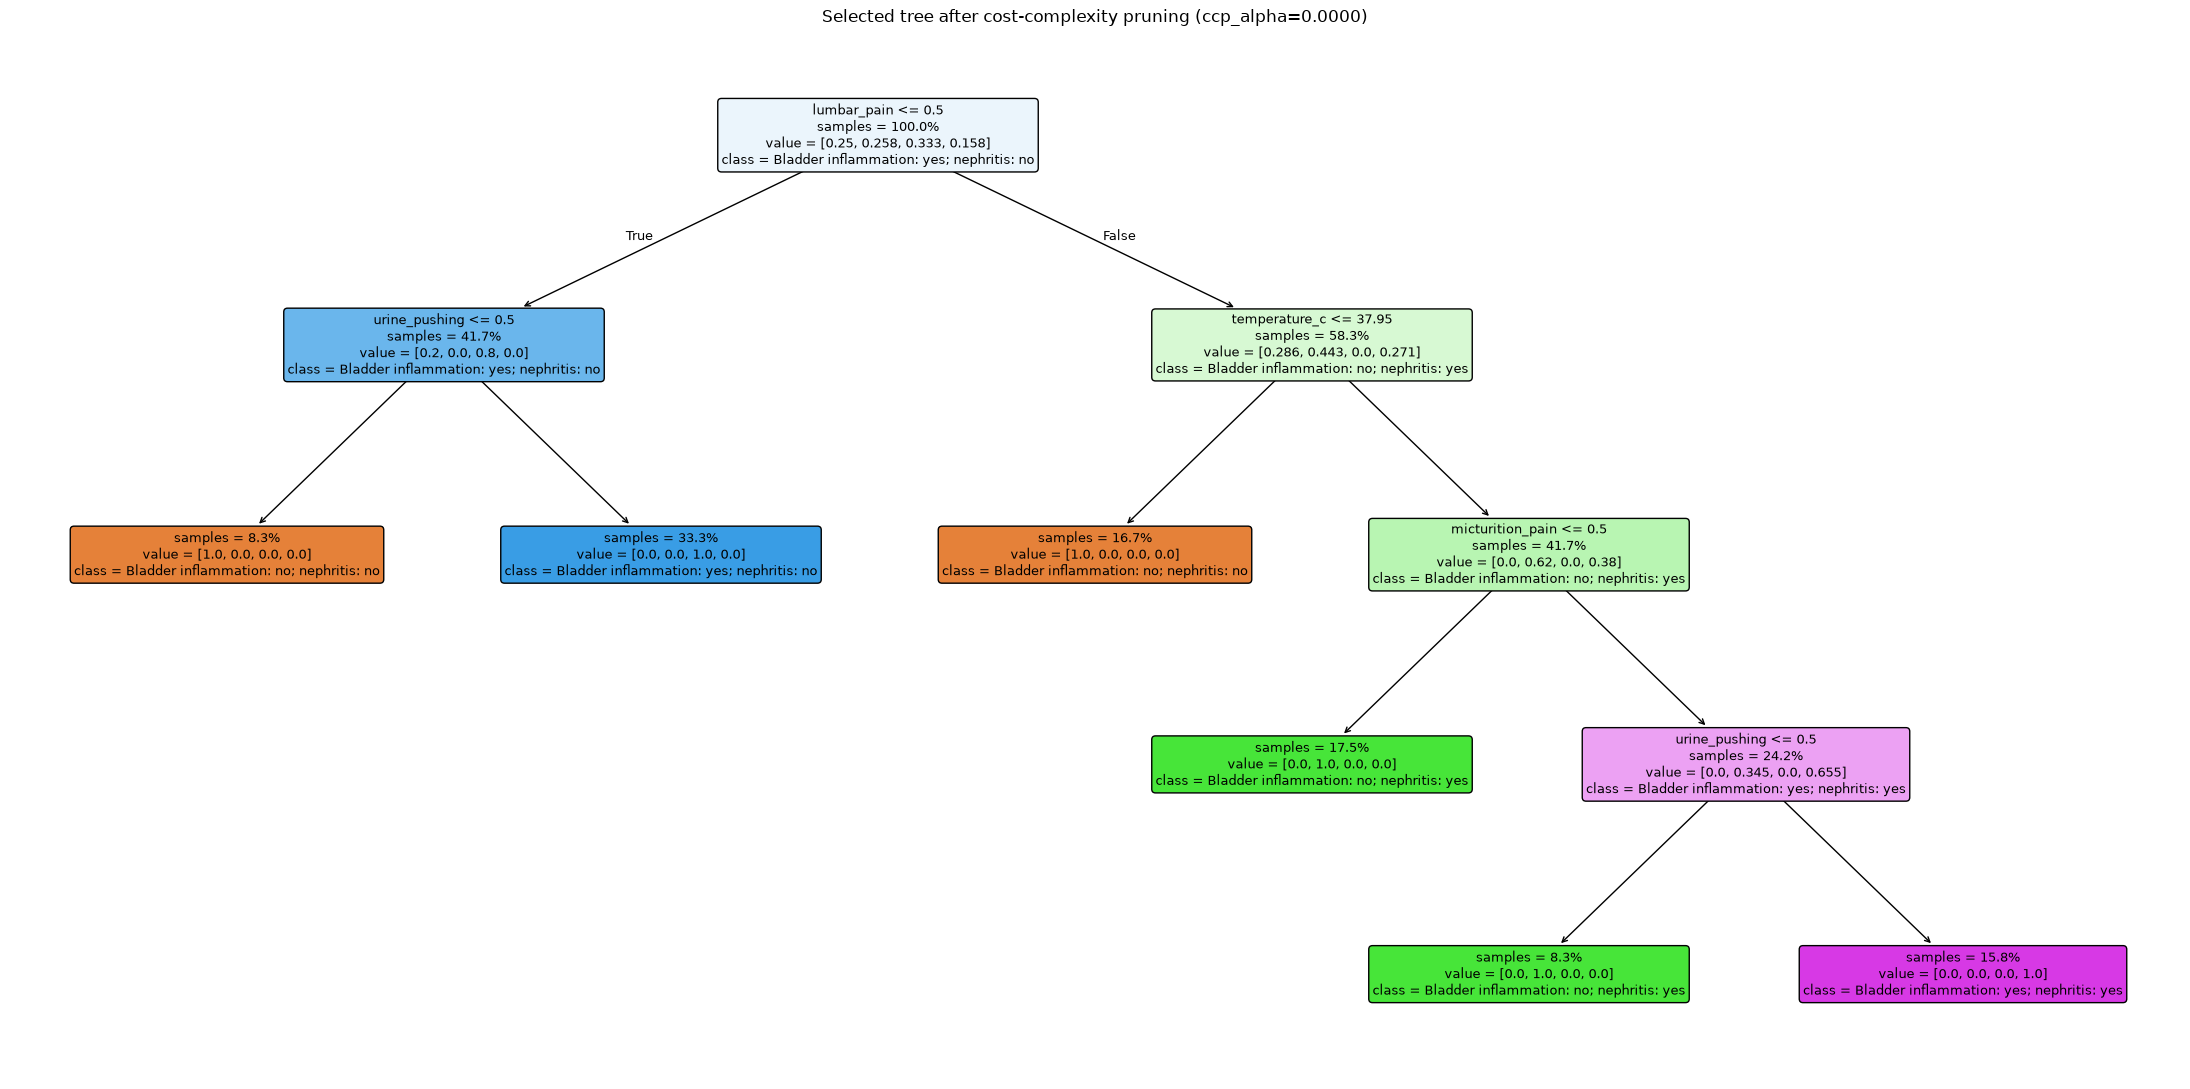

IF-THEN rules for the selected tree:
|--- lumbar_pain <= 0.50
|   |--- urine_pushing <= 0.50
|   |   |--- class: Bladder inflammation: no; nephritis: no
|   |--- urine_pushing >  0.50
|   |   |--- class: Bladder inflammation: yes; nephritis: no
|--- lumbar_pain >  0.50
|   |--- temperature_c <= 37.95
|   |   |--- class: Bladder inflammation: no; nephritis: no
|   |--- temperature_c >  37.95
|   |   |--- micturition_pain <= 0.50
|   |   |   |--- class: Bladder inflammation: no; nephritis: yes
|   |   |--- micturition_pain >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: Bladder inflammation: no; nephritis: yes
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: Bladder inflammation: yes; nephritis: yes



In [4]:
pruning_path = DecisionTreeClassifier(random_state=552).cost_complexity_pruning_path(X, y)
candidate_alphas = np.unique(pruning_path.ccp_alphas)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)
folds = list(cv.split(X, y))

pruning_results = []
for alpha in candidate_alphas:
    fold_accuracies = []
    for train_index, validation_index in folds:
        candidate = DecisionTreeClassifier(random_state=552, ccp_alpha=alpha)
        candidate.fit(X.iloc[train_index], y.iloc[train_index])
        fold_accuracies.append(
            accuracy_score(y.iloc[validation_index], candidate.predict(X.iloc[validation_index]))
        )

    fitted_candidate = DecisionTreeClassifier(random_state=552, ccp_alpha=alpha).fit(X, y)
    pruning_results.append(
        {
            "ccp_alpha": alpha,
            "mean_cv_accuracy": np.mean(fold_accuracies),
            "standard_error": np.std(fold_accuracies, ddof=1) / np.sqrt(len(fold_accuracies)),
            "leaves": fitted_candidate.get_n_leaves(),
            "nodes": fitted_candidate.tree_.node_count,
        }
    )

pruning_results = pd.DataFrame(pruning_results)
best_row = pruning_results.loc[pruning_results["mean_cv_accuracy"].idxmax()]
one_se_threshold = best_row["mean_cv_accuracy"] - best_row["standard_error"]
eligible = pruning_results[
    pruning_results["mean_cv_accuracy"] >= one_se_threshold
]
selected_row = eligible.loc[eligible["ccp_alpha"].idxmax()]
selected_alpha = selected_row["ccp_alpha"]
pruned_tree = DecisionTreeClassifier(
    random_state=552, ccp_alpha=selected_alpha
).fit(X, y)

display(pruning_results.round(4))
print(
    f"Selected ccp_alpha={selected_alpha:.6f}; "
    f"one-standard-error threshold={one_se_threshold:.3f}; "
    f"leaves={pruned_tree.get_n_leaves()}; nodes={pruned_tree.tree_.node_count}; "
    f"training accuracy={accuracy_score(y, pruned_tree.predict(X)):.3f}"
)

plt.figure(figsize=(22, 11))
plt.errorbar(
    pruning_results["ccp_alpha"],
    pruning_results["mean_cv_accuracy"],
    yerr=pruning_results["standard_error"],
    marker="o",
    capsize=4,
)
plt.axhline(one_se_threshold, color="gray", linestyle="--", label="one-SE threshold")
plt.axvline(selected_alpha, color="tab:red", linestyle=":", label="selected alpha")
plt.xlabel("Cost-complexity parameter (ccp_alpha)")
plt.ylabel("Five-fold joint-classification accuracy")
plt.title("Cost-complexity pruning: cross-validation accuracy")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(22, 11))
plot_tree(
    pruned_tree,
    feature_names=feature_names,
    class_names=pruned_tree.classes_,
    filled=True,
    rounded=True,
    proportion=True,
    impurity=False,
    fontsize=9,
)
plt.title(f"Selected tree after cost-complexity pruning (ccp_alpha={selected_alpha:.4f})")
plt.tight_layout()
plt.show()

print("IF-THEN rules for the selected tree:")
print(export_text(pruned_tree, feature_names=feature_names, decimals=2))